# Dear Canada — Modelling
LDA topic modelling · Character vector embeddings · UMAP · Semantic search

**Before running:** activate your `dear-canada` conda environment and launch Jupyter from the `Dear Canada/` project root.

Lines marked `# >>>` are yours to edit.

In [1]:
# ── Imports ───────────────────────────────────────────────────────────────────
import sys
sys.path.insert(0, "..")   # makes Dear Canada/ visible to Python

import importlib
import config
import CLS_utils
importlib.reload(config)
importlib.reload(CLS_utils)

from CLS_utils import *


print("Imports OK.")

Imports OK.


In [2]:
# ── Load text data ────────────────────────────────────────────────────────────
# >>> To load only specific books pass a list, e.g. books=["SofS", "FitS"]
book_dfs, data = load_texts(books=None)   # >>>

OK  SofS: 9 chapters loaded.
OK  FitS: 18 chapters loaded.
OK  DRtoF: 14 chapters loaded.
OK  PasWide: 1 chapters loaded.
OK  NbutC: 14 chapters loaded.
OK  AinUTL: 13 chapters loaded.

Total chapters across all books: 69


---
## 1 · LDA topic modelling

Latent Dirichlet Allocation discovers clusters of words ('topics') that tend to appear together across chapters. Outputs a word-cloud grid showing the top words per topic, then a separate heatmap per book showing which topics dominate which chapters.

/Users/sophiebird/anaconda3/envs/dearcanadaenv/lib/python3.11/site-packages/sklearn/feature_extraction/text.py:411: UserWarning: Your stop_words may be inconsistent with your preprocessing. Tokenizing the stop words generated tokens ['pa'] not in stop_words.
  warnings.warn(


LDA fitted: 3 topics over 68 chapters.


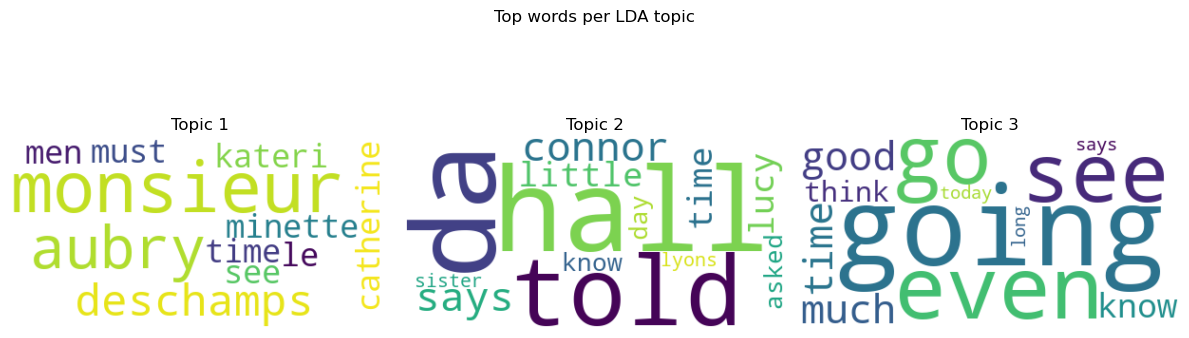

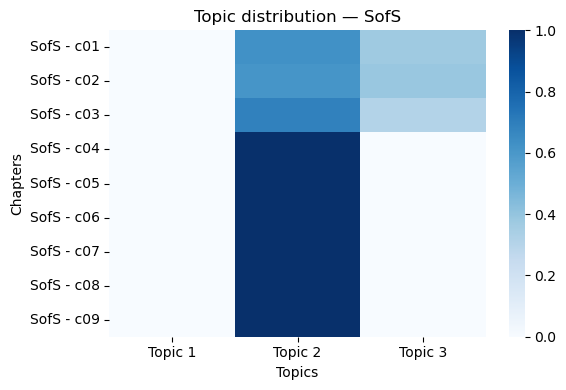

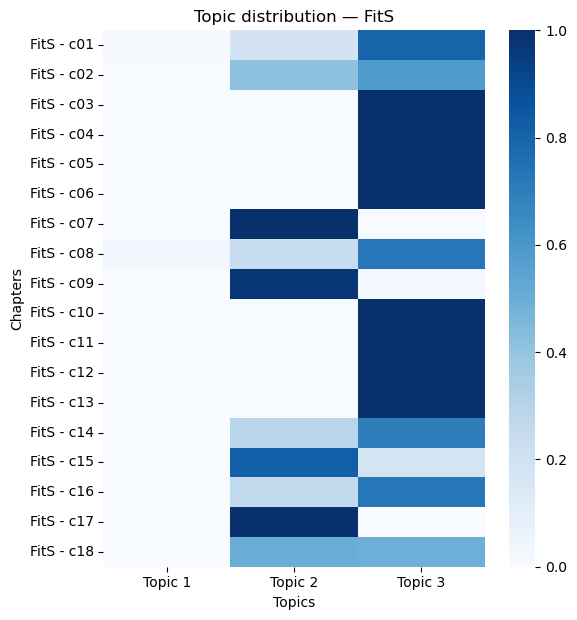

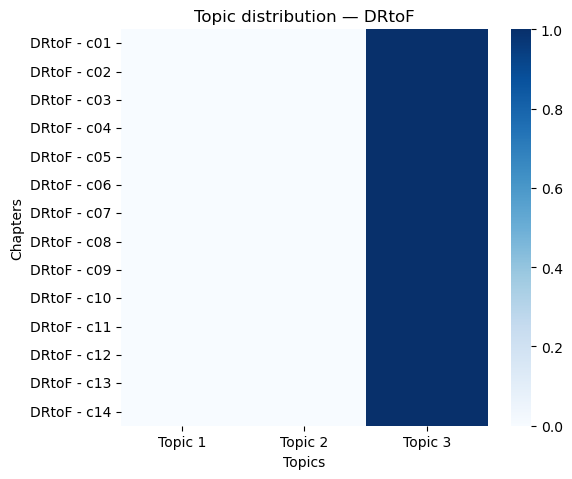

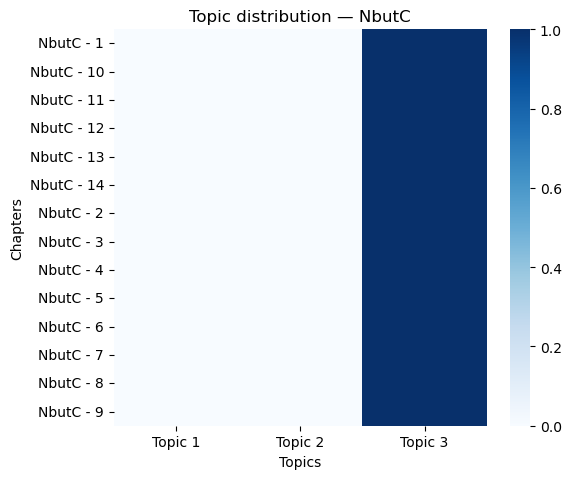

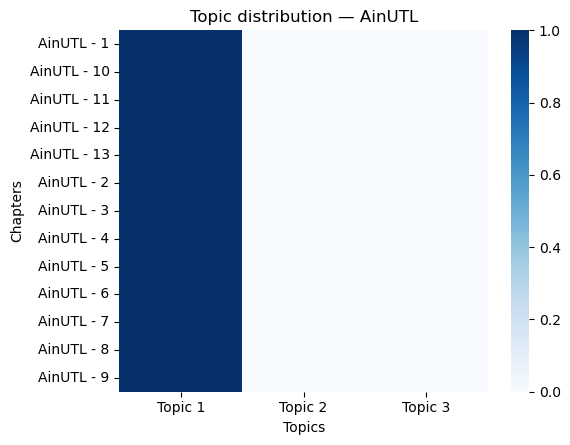

In [9]:
# >>> Tune these
N_TOPICS    = 3   # try 3–8; more = finer but harder to label
N_TOP_WORDS = 15

# >>> Restrict to specific books, or None for all
BOOKS_FOR_LDA = ["SofS", "FitS", "DRtoF", "AinUTL", "NbutC"]   # e.g. ["SofS", "FitS"]

lda_results = run_lda(data, n_topics=N_TOPICS, n_top_words=N_TOP_WORDS, book_filter=BOOKS_FOR_LDA)

---
## 2 · Character vector embeddings

### How it works
Each *Dear Canada* book is narrated in first person, so "I" always refers to the protagonist. Before embedding we replace first-person pronouns with the girl's name (from `config.py`) so the model can distinguish speakers across books.

Every sentence is then encoded with `sentence-transformers` (a fine-tuned BERT model). Each sentence becomes a 384-dimensional vector capturing semantic content. We mean-pool all sentence vectors per book to get a single representative *character embedding*.

**What the similarity scores capture:** shared vocabulary, emotional tone, themes, and narrative style — not just surface word overlap.

In [4]:
# ── 2.1  Pronoun substitution ─────────────────────────────────────────────────

# >>> Books to exclude from embedding (e.g. if French text causes issues)
SKIP_BOOKS = []   # e.g. ["AinUTL"]

substituted_texts = build_embedding_corpus(book_dfs, skip_books=SKIP_BOOKS)

OK  SofS (SofS): pronouns substituted.
OK  FitS (FitS): pronouns substituted.
OK  DRtoF (DRtoF): pronouns substituted.
OK  PasWide (PasWide): pronouns substituted.
OK  NbutC (NbutC): pronouns substituted.
OK  AinUTL (AinUTL): pronouns substituted.


In [5]:
# ── 2.2  Generate BERT embeddings ─────────────────────────────────────────────
# Downloads ~90 MB on first run; cached afterwards.
# >>> Swap model_name for "all-mpnet-base-v2" if you want higher quality and
#     have time to spare (slower, same API).

book_embeddings, sentence_emb_data = generate_embeddings(
    substituted_texts,
    model_name="all-MiniLM-L6-v2"   # >>>
)

Loading model: all-MiniLM-L6-v2 …


Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

BertModel LOAD REPORT from: sentence-transformers/all-MiniLM-L6-v2
Key                     | Status     |  | 
------------------------+------------+--+-
embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Model loaded.

  SofS: encoding 2,273 sentences … done. Shape: (2273, 384)
  FitS: encoding 1,942 sentences … done. Shape: (1942, 384)
  DRtoF: encoding 2,981 sentences … done. Shape: (2981, 384)
  PasWide: encoding 3,128 sentences … done. Shape: (3128, 384)
  NbutC: encoding 2,885 sentences … done. Shape: (2885, 384)
  AinUTL: encoding 3,170 sentences … done. Shape: (3170, 384)


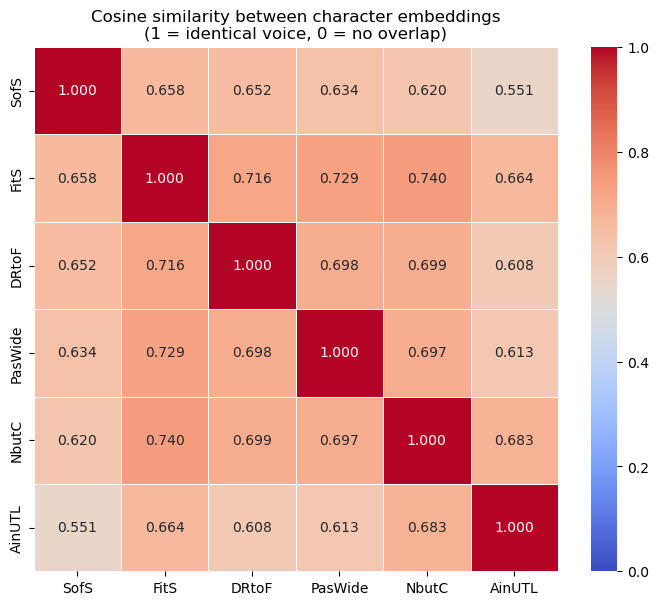

Most similar pairs:
  FitS ↔ NbutC: 0.7398
  FitS ↔ PasWide: 0.7293
  FitS ↔ DRtoF: 0.7163
  DRtoF ↔ NbutC: 0.6991
  DRtoF ↔ PasWide: 0.6981


In [6]:
# ── 2.3  Cosine similarity matrix ─────────────────────────────────────────────
plot_similarity_matrix(book_embeddings)

Fitting UMAP on 16,379 vectors …


/Users/sophiebird/anaconda3/envs/dearcanadaenv/lib/python3.11/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
OMP: Info #276: omp_set_nested routine deprecated, please use omp_set_max_active_levels instead.


Done.


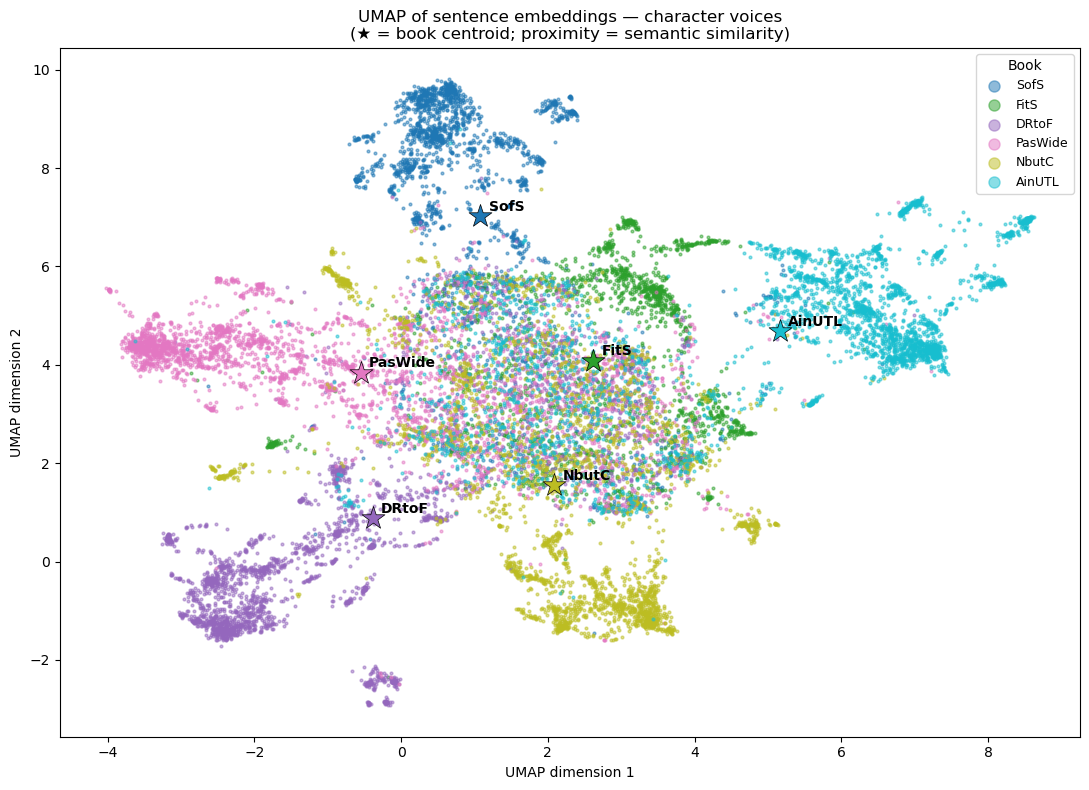

In [7]:
# ── 2.4  UMAP projection ──────────────────────────────────────────────────────
# Each dot = one sentence; colour = book.
# Stars mark each book's centroid.
# >>> n_neighbors: larger = more global structure; min_dist: smaller = tighter clusters

plot_umap(sentence_emb_data, n_neighbors=15, min_dist=0.1)

In [8]:
# ── 2.5  Semantic sentence search ─────────────────────────────────────────────
# Find the most thematically similar sentences to any query across all books.
# Useful for spotting shared emotional moments or narrative echoes.

# >>> Edit freely
QUERY        = "I was frightened but I did not show it."   # >>>
EXCLUDE_BOOK = None   # >>> set to a book name to exclude it from results
TOP_K        = 10     # >>>

find_similar_sentences(
    QUERY, sentence_emb_data,
    exclude_book=EXCLUDE_BOOK,
    top_k=TOP_K
)

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

BertModel LOAD REPORT from: sentence-transformers/all-MiniLM-L6-v2
Key                     | Status     |  | 
------------------------+------------+--+-
embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Query: "I was frightened but I did not show it."

Top 10 most similar sentences:

   1. [FitS] (sim=0.6337)
      Fits wasn’t frightened, not at all.

   2. [DRtoF] (sim=0.5532)
      It was scary getting on board.

   3. [NbutC] (sim=0.5279)
      We had been assured that they were friendly, however, and willing to share their land with us, so we were not frightened when these two appeared.

   4. [NbutC] (sim=0.5119)
      He was frightened at first, but now he thinks this is all just a great adventure.

   5. [NbutC] (sim=0.5111)
      That is very frightening.

   6. [NbutC] (sim=0.5035)
      Terrified he was when he saw that blood streaming out.

   7. [DRtoF] (sim=0.4983)
      We all got soaking wet and it was scary.

   8. [DRtoF] (sim=0.4940)
      It looked spooky when the light shone on it.

   9. [SofS] (sim=0.4928)
      Ma looked frightened when he mentioned the word 
storm
.

  10. [NbutC] (sim=0.4731)
      That was terrifying enough.

